# Dimensionality Reduction and Spectral Clustering Project


This project implements dimensionality reduction techniques based on graph embeddings and similarities (Spectral Embedding (Laplacian Eigenmaps), Isomap, Locally Linear Embedding (LLE), t-SNE), followed by spectral clustering analysis. The goal is to reduce high-dimensional data to 2D representations while preserving important structural information, then apply clustering to identify meaningful groups. 

In [2]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
import networkx as nx

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import SpectralEmbedding, Isomap, LocallyLinearEmbedding, TSNE
from sklearn.cluster import SpectralClustering
from sklearn.neighbors import NearestNeighbors, NearestCentroid
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    adjusted_rand_score, 
    normalized_mutual_info_score,
    silhouette_score, 
    accuracy_score, 
    confusion_matrix
)

import torch
import torchvision
import torchvision.transforms as transforms

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# Set random state for reproducibility
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# Configure plotting style
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.1)
plt.rcParams['figure.figsize'] = [12, 8]
plt.rcParams['figure.dpi'] = 100

print("Libraries imported successfully!")
print(f"Random state: {RANDOM_STATE}")

Libraries imported successfully!
Random state: 42


## 2. Dataset Loading and Preprocessing

We will work with two classification datasets:
- **CIFAR-10**: 60,000 32×32 color images in 10 classes
- **MNIST**: 70,000 28×28 grayscale images of handwritten digits

In [3]:
SUB_SAMPLE = 2000  # Number of samples to use from each dataset

# Load datasets inline (no function) - CIFAR-10 then MNIST
print("Loading datasets...")

# CIFAR-10 preprocessing and loading 
mean = (0.49139968, 0.48215827, 0.44653124)
std = (0.24703233, 0.24348505, 0.26158768)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
    torch.flatten
])

download_flag = not os.path.isdir('./data/cifar-10-batches-py')
dataset_cifar = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=download_flag, transform=transform
)
loader = torch.utils.data.DataLoader(
    dataset=dataset_cifar, shuffle=True, batch_size=10000, num_workers=2
)
images, labels = next(iter(loader))
X_cifar = images.numpy()
y_cifar = labels.numpy()

indices = rng.choice(len(X_cifar), SUB_SAMPLE, replace=False) 
X_cifar = X_cifar[indices]
y_cifar = y_cifar[indices]
scaler = StandardScaler()
X_cifar = scaler.fit_transform(X_cifar)

target_names = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

print(f"Loaded CIFAR10: {X_cifar.shape[0]} samples, {X_cifar.shape[1]} features, {len(np.unique(y_cifar))} classes")

# MNIST preprocessing and loading 
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
    torch.flatten
])

download_flag = not os.path.isdir('./data/MNIST')
dataset_mnist = torchvision.datasets.MNIST(
    root='./data', train=True, download=download_flag, transform=transform
)
loader = torch.utils.data.DataLoader(
    dataset=dataset_mnist, shuffle=True, batch_size=10000, num_workers=2
)
images, labels = next(iter(loader))
X_mnist = images.numpy()
y_mnist = labels.numpy()

print(f"Loaded MNIST: {X_mnist.shape[0]} samples, {X_mnist.shape[1]} features, {len(np.unique(y_mnist))} classes")


indices = rng.choice(len(X_mnist), SUB_SAMPLE, replace=False) 
X_mnist = X_mnist[indices]
y_mnist = y_mnist[indices]
scaler = StandardScaler()
X_mnist = scaler.fit_transform(X_mnist)

# Store datasets in a dictionary for easy access
datasets = {
    'CIFAR-10': (X_cifar, y_cifar),
    'MNIST': (X_mnist, y_mnist),
}

print("\nDatasets loaded successfully!")

Loading datasets...
Loaded CIFAR10: 2000 samples, 3072 features, 10 classes
Loaded MNIST: 10000 samples, 784 features, 10 classes

Datasets loaded successfully!


## 3. From-Scratch Spectral Embedding Implementation

Spectral embedding (also known as Laplacian Eigenmaps) is a manifold learning technique that preserves local neighborhood relationships in the data. 

### The algorithm consists of several key steps:

1. **Graph Construction**: Build a k-nearest neighbors graph
2. **Affinity Matrix**: Compute edge weights using a kernel function
3. **Graph Laplacian**: Construct the Laplacian matrix
4. **Eigenvalue Decomposition**: Find the embedding coordinates
5. **Dimensionality Reduction**: Project to lower dimensions

### Mathematical Foundation
- **Adjacency Matrix W**: $W_{ij} = \exp(-\frac{\|x_i - x_j\|^2}{2\sigma^2})$ for k-nearest neighbors
- **Degree Matrix D**: Diagonal matrix with $D_{ii} = \sum_j W_{ij}$
- **Graph Laplacian L**: $L = D - W$
- **Normalized Laplacian**: $L_{norm} = D^{-1/2} L D^{-1/2}$
- **Embedding**: The eigenvectors corresponding to the smallest non-zero eigenvalues



In [4]:
def spectral_embedding(X, n_components=2, n_neighbors=10):
    X = np.asarray(X)
    n_samples = X.shape[0]

    # Get k+1 neighbors since sklearn includes the point itself
    nbrs = NearestNeighbors(n_neighbors=n_neighbors + 1, algorithm='auto').fit(X)
    distances, indices = nbrs.kneighbors(X)

    # Build adjacency matrix
    W = np.zeros((n_samples, n_samples))
    for i in range(n_samples):
        # Start at 1 to skip self-loops
        for k in range(1, n_neighbors + 1):
            j = indices[i, k]
            W[i, j] = 1.0

    # Symmetrize the graph
    W = 0.5 * (W + W.T)

    # Compute Normalized Laplacian inputs
    degrees = np.sum(W, axis=1)
    degrees[degrees < 1e-12] = 1e-12 # Prevent division by zero
    
    D_inv_sqrt = np.diag(1.0 / np.sqrt(degrees))
    
    # Calculate M = D^-0.5 * W * D^-0.5
    M = D_inv_sqrt @ W @ D_inv_sqrt
    
    # Eigendecomposition
    vals, vecs = np.linalg.eigh(M)
    
    # Sort descending
    idx = np.argsort(vals)[::-1]
    vecs = vecs[:, idx]
    
    # Drop the first eigenvector (constant) and scale
    embedding = vecs[:, 1:n_components + 1]
    embedding = D_inv_sqrt @ embedding

    return embedding

In [5]:
def get_embedding(method_name, X, n_components=2, random_state=RANDOM_STATE):
    """Return a 2D embedding of X using the named method."""

    if method_name == 'Spectral(Scratch)':
        print("Using Spectral Embedding from Scratch")
        X_emb = spectral_embedding(X, n_components=n_components, n_neighbors=10)
    elif method_name == 'Spectral(Library)':
        print("Using Spectral Embedding from scikit-learn")
        emb = SpectralEmbedding(n_components=n_components, n_neighbors=10, random_state=random_state)
        X_emb = emb.fit_transform(X)
    elif method_name == 'Isomap':
        print("Using Isomap from scikit-learn")
        emb = Isomap(n_components=n_components, n_neighbors=10)
        X_emb = emb.fit_transform(X)
    elif method_name == 'LLE':
        print
        emb = LocallyLinearEmbedding(n_components=n_components, n_neighbors=10, method='standard')
        X_emb = emb.fit_transform(X)
    elif method_name == 't-SNE':
        print("Using t-SNE from scikit-learn")
        emb = TSNE(n_components=n_components, random_state=random_state, init='pca')
        X_emb = emb.fit_transform(X)
    return X_emb

## 4. Library Implementations and Comparison

Now that we understand the algorithm from scratch, let's compare it with optimized library implementations from scikit-learn.

Using Spectral Embedding from Scratch
Using Spectral Embedding from scikit-learn
Using Isomap from scikit-learn
Using t-SNE from scikit-learn
Saved CIFAR-10 clustering result figure to: figures\cifar-10_spectral_clustering_output.png


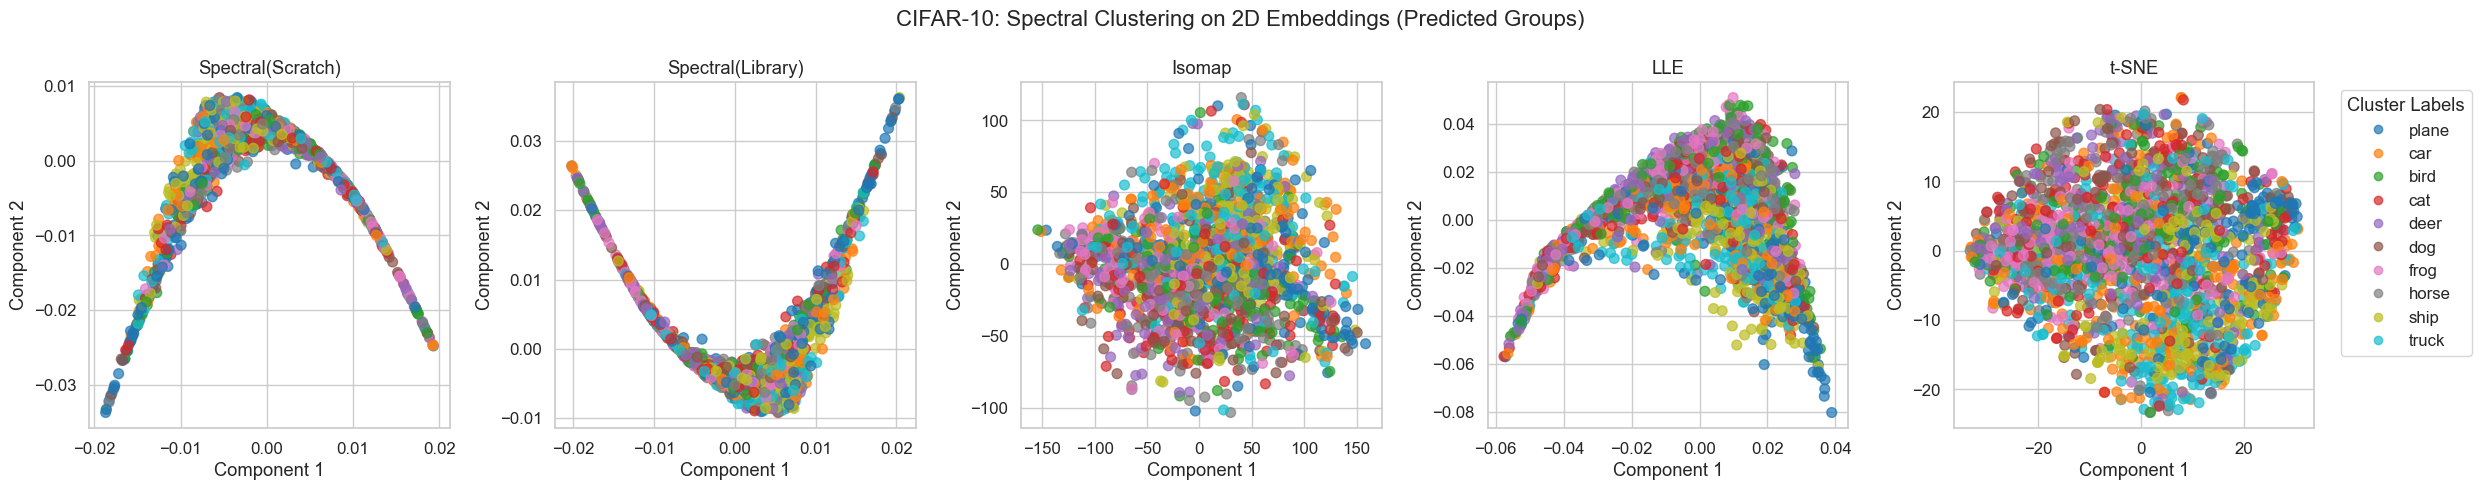

Using Spectral Embedding from Scratch
Using Spectral Embedding from scikit-learn
Using Isomap from scikit-learn
Using t-SNE from scikit-learn
Saved MNIST clustering result figure to: figures\mnist_spectral_clustering_output.png


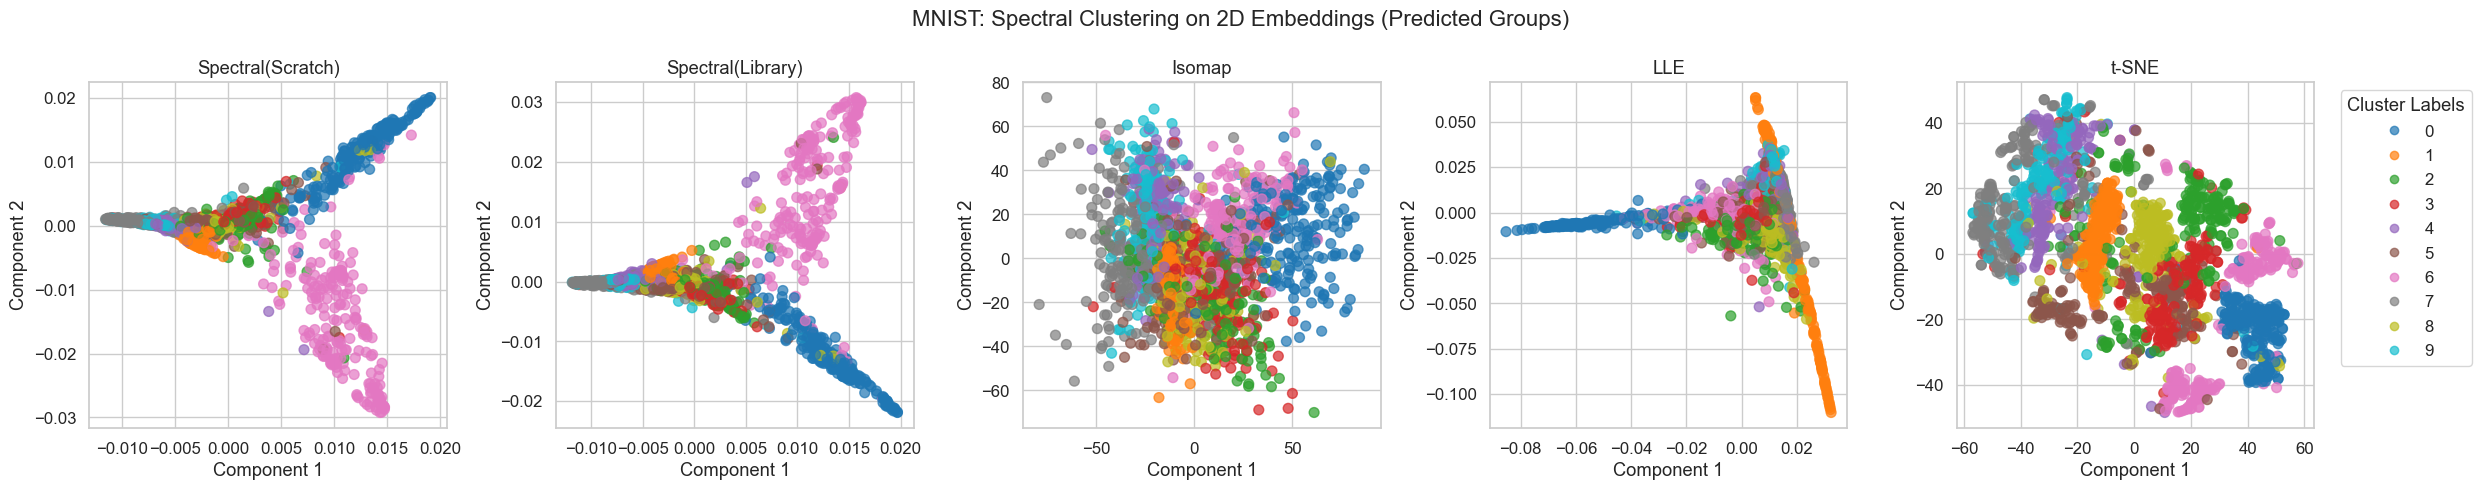

In [6]:
# Plotting comparison for both MNIST and CIFAR-10 datasets using all methods
methods_to_compare = ['Spectral(Scratch)', 'Spectral(Library)', 'Isomap', 'LLE', 't-SNE']

def get_embeddings_for_all_methods(X, y, n_samples=2000):
    indices = rng.choice(len(X), n_samples, replace=False) if len(X) > n_samples else np.arange(len(X))
    X_small = X[indices]
    y_small = y[indices]
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_small)
    embeddings = {}
    for method in methods_to_compare:
        embeddings[method] = get_embedding(method, X_scaled)
    return embeddings, y_small

for dataset_name, (X, y) in datasets.items():
    # 1. Get the 2D embeddings as before
    embeddings, y_small = get_embeddings_for_all_methods(X, y, n_samples=2000)
    
    fig, axes = plt.subplots(1, 5, figsize=(25, 5))
    fig.suptitle(f'{dataset_name}: Spectral Clustering on 2D Embeddings (Predicted Groups)', fontsize=16)
    
    for i, method in enumerate(methods_to_compare):
        ax = axes[i]
        emb = embeddings[method]  # This is the 2D data (N x 2)
        
        # Apply Spectral Clustering on the 2D data
        sc = SpectralClustering(n_clusters=10, affinity='nearest_neighbors', random_state=42)
        
        # Get the labels found by the algorithm
        cluster_labels = sc.fit_predict(emb)
        
        # PLOTTING 
        #scatter = ax.scatter(emb[:, 0], emb[:, 1], c=cluster_labels, cmap='tab10', alpha=0.7, s=50)
        scatter = ax.scatter(emb[:, 0], emb[:, 1], c=y_small, cmap='tab10', alpha=0.7, s=50)

        ax.set_title(f'{method}')
        ax.set_xlabel('Component 1')
        ax.set_ylabel('Component 2')
        
        
    # Legend showing the Cluster Labels
    if dataset_name == 'CIFAR-10':
        handles, _ = scatter.legend_elements(prop="colors")
        plt.legend(handles, target_names, title="Cluster Labels", bbox_to_anchor=(1.05, 1), loc='upper left')
    else:
        plt.legend(*scatter.legend_elements(), title="Cluster Labels", bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    os.makedirs('figures', exist_ok=True)
    
    # Changed filename to differentiate from the ground truth plot
    comp_path = os.path.join('figures', f'{dataset_name.lower()}_spectral_clustering_output.png')
    fig.savefig(comp_path, dpi=200, bbox_inches='tight')
    print(f"Saved {dataset_name} clustering result figure to: {comp_path}")
    plt.show()
    

Processing CIFAR-10...
Using Spectral Embedding from Scratch
Using Spectral Embedding from scikit-learn
Using Isomap from scikit-learn
Using t-SNE from scikit-learn


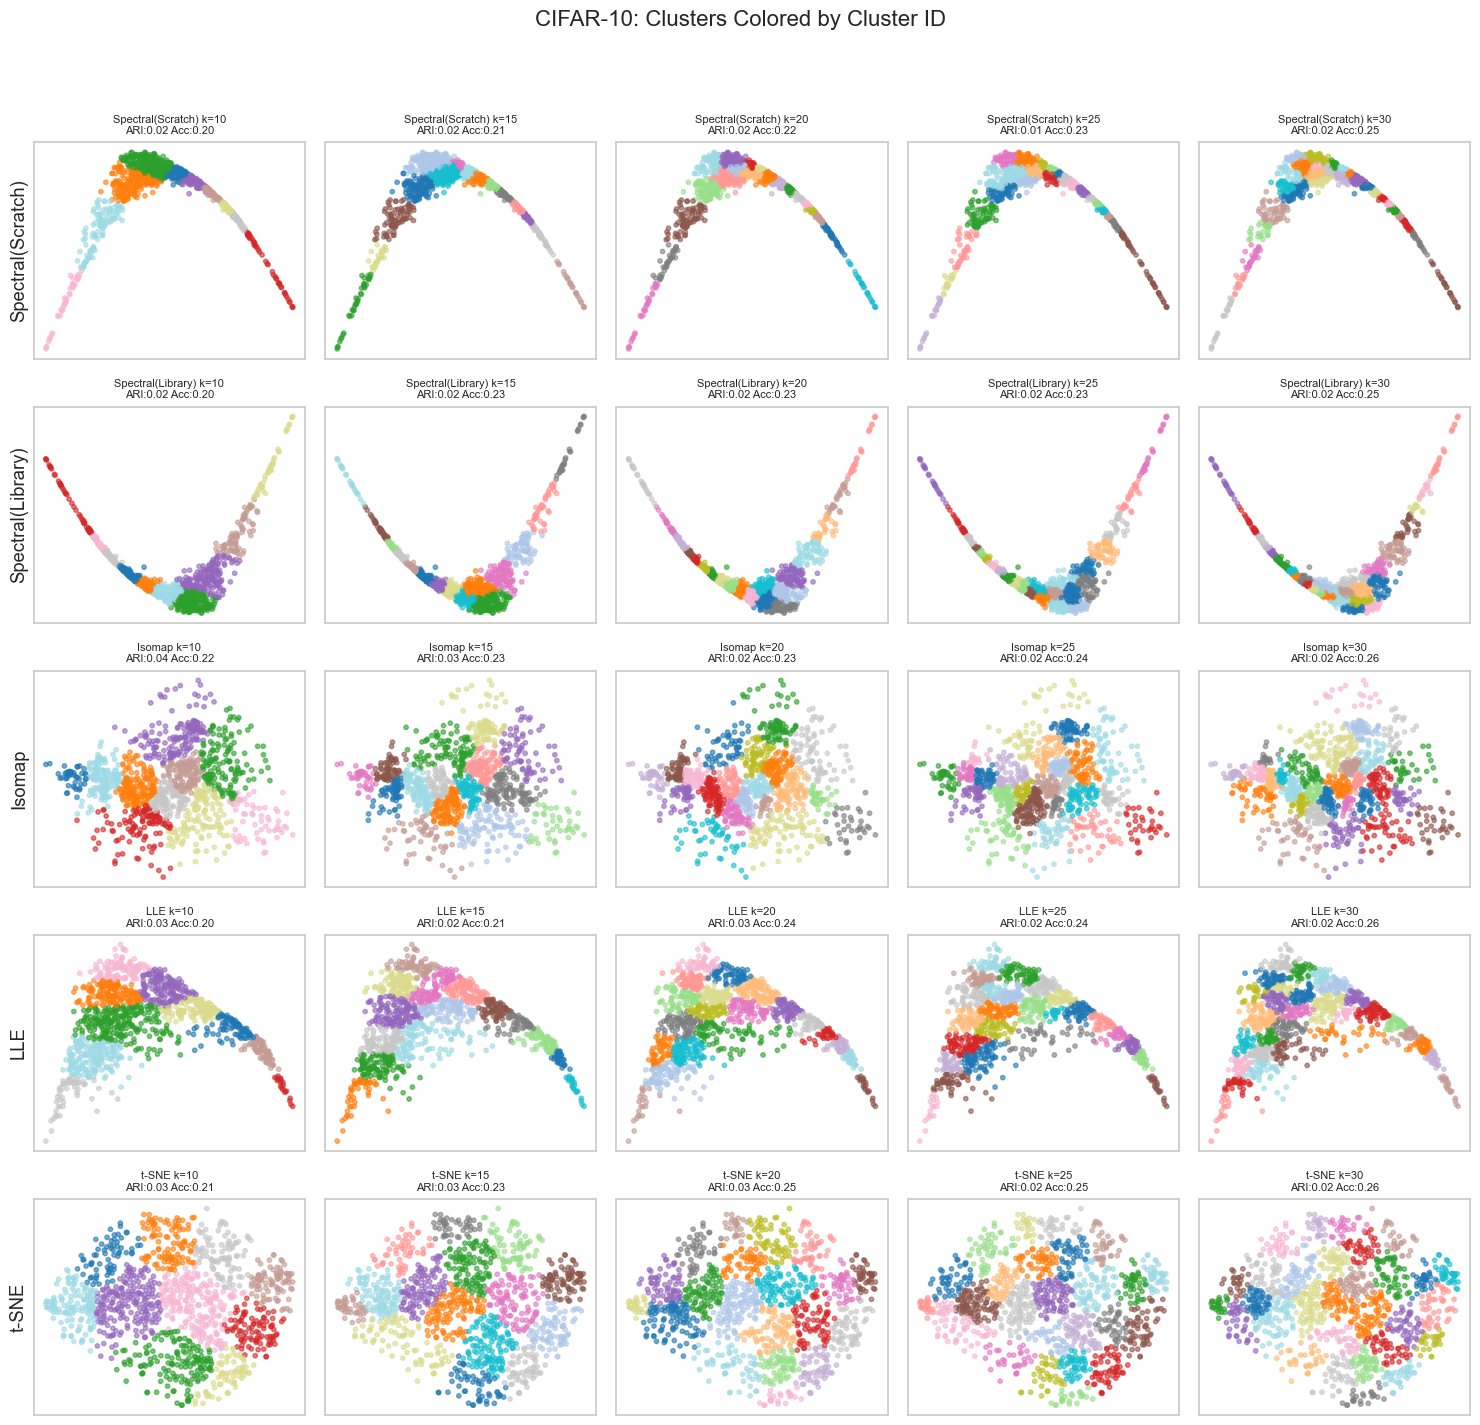


Metrics Summary (Sorted by ARI):
           Method  k   ARI   Acc   NMI   Sil
           Isomap 10 0.037 0.223 0.094 0.299
              LLE 10 0.030 0.203 0.082 0.351
            t-SNE 10 0.030 0.212 0.090 0.347
            t-SNE 15 0.028 0.233 0.109 0.341
           Isomap 15 0.028 0.231 0.100 0.329
            t-SNE 20 0.028 0.250 0.121 0.313
              LLE 20 0.026 0.237 0.109 0.336
              LLE 15 0.024 0.210 0.097 0.358
Spectral(Scratch) 10 0.024 0.200 0.060 0.419
            t-SNE 25 0.024 0.253 0.129 0.301
           Isomap 20 0.023 0.234 0.106 0.306
Spectral(Scratch) 15 0.023 0.215 0.074 0.393
Spectral(Library) 15 0.023 0.225 0.076 0.417
Spectral(Library) 10 0.022 0.195 0.060 0.426
            t-SNE 30 0.021 0.263 0.137 0.302
              LLE 25 0.021 0.242 0.117 0.324
           Isomap 25 0.021 0.240 0.114 0.298
Spectral(Library) 25 0.020 0.234 0.103 0.384
Spectral(Scratch) 20 0.020 0.224 0.085 0.391
              LLE 30 0.019 0.263 0.136 0.313
           Isomap 30 

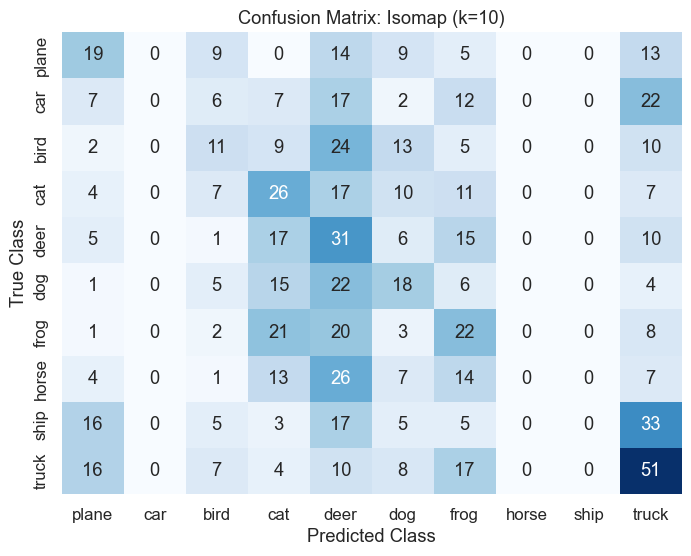

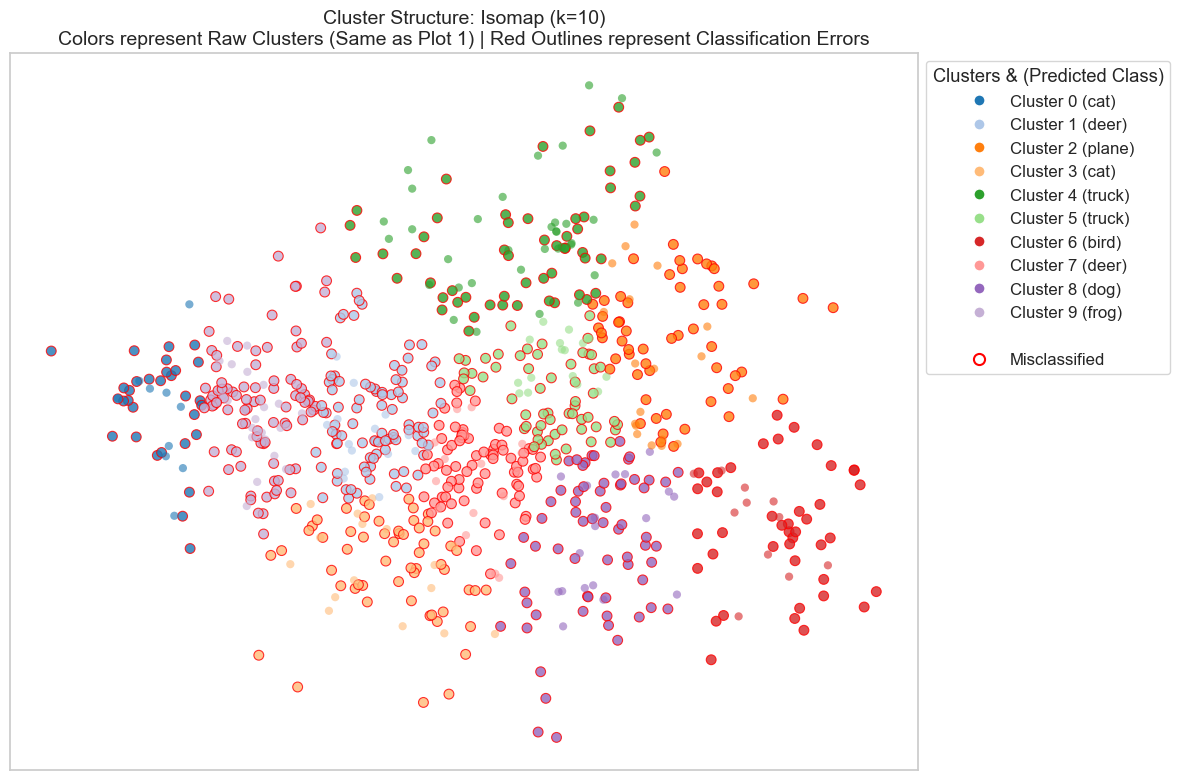

Processing MNIST...
Using Spectral Embedding from Scratch
Using Spectral Embedding from scikit-learn
Using Isomap from scikit-learn
Using t-SNE from scikit-learn


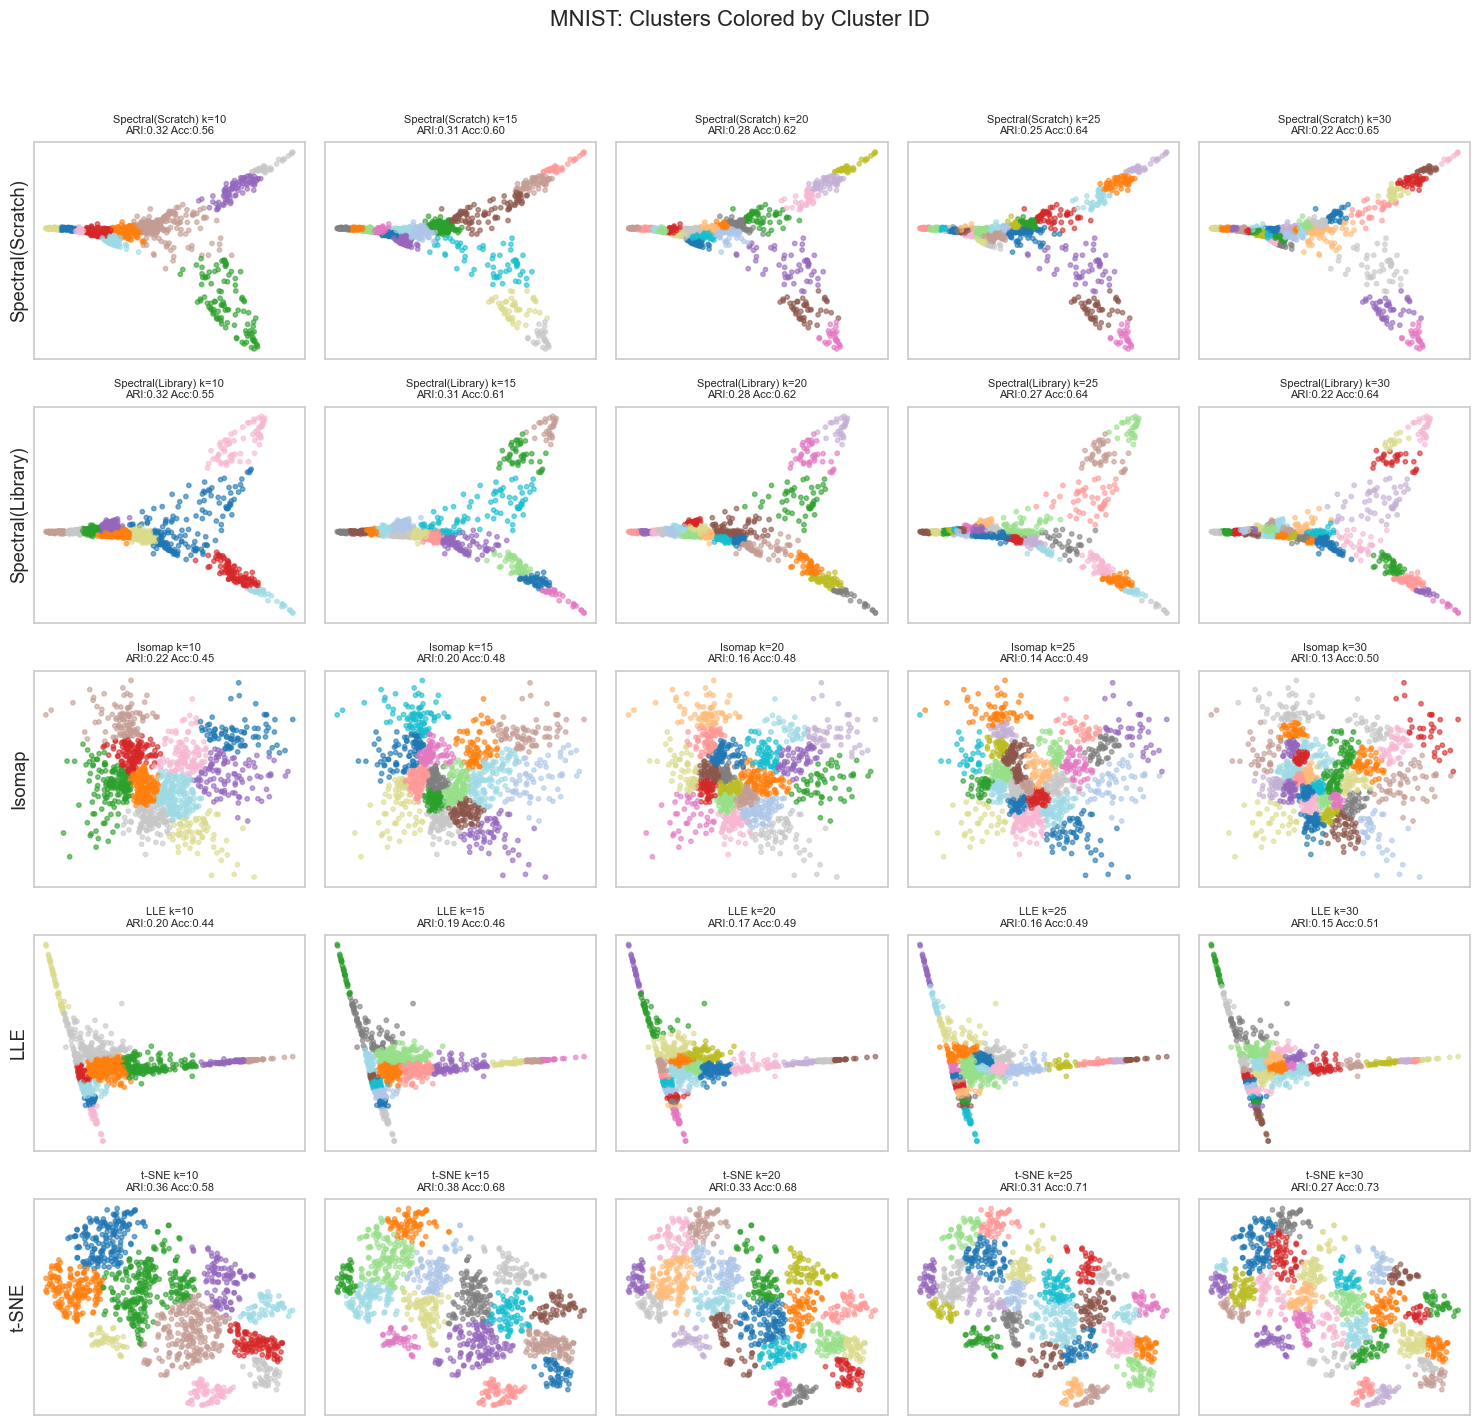


Metrics Summary (Sorted by ARI):
           Method  k   ARI   Acc   NMI   Sil
            t-SNE 15 0.385 0.677 0.574 0.415
            t-SNE 10 0.356 0.579 0.550 0.416
            t-SNE 20 0.329 0.681 0.548 0.373
Spectral(Scratch) 10 0.323 0.560 0.512 0.411
Spectral(Library) 10 0.322 0.545 0.517 0.416
Spectral(Scratch) 15 0.315 0.604 0.513 0.416
            t-SNE 25 0.310 0.715 0.564 0.379
Spectral(Library) 15 0.310 0.613 0.504 0.418
Spectral(Scratch) 20 0.284 0.620 0.503 0.396
Spectral(Library) 20 0.283 0.620 0.504 0.391
Spectral(Library) 25 0.274 0.636 0.503 0.387
            t-SNE 30 0.274 0.731 0.559 0.356
Spectral(Scratch) 25 0.249 0.636 0.498 0.388
Spectral(Library) 30 0.224 0.640 0.492 0.363
Spectral(Scratch) 30 0.219 0.645 0.491 0.383
           Isomap 10 0.218 0.454 0.372 0.343
              LLE 10 0.201 0.439 0.389 0.419
           Isomap 15 0.199 0.479 0.386 0.292
              LLE 15 0.192 0.459 0.397 0.366
              LLE 20 0.173 0.492 0.385 0.369
           Isomap 20 

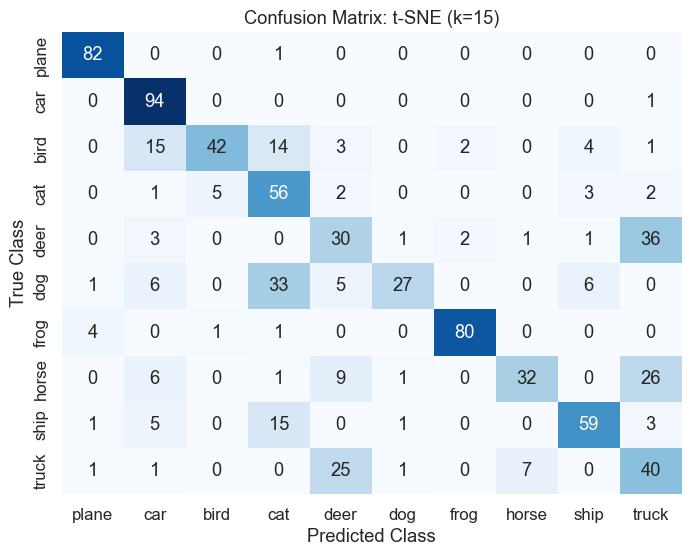

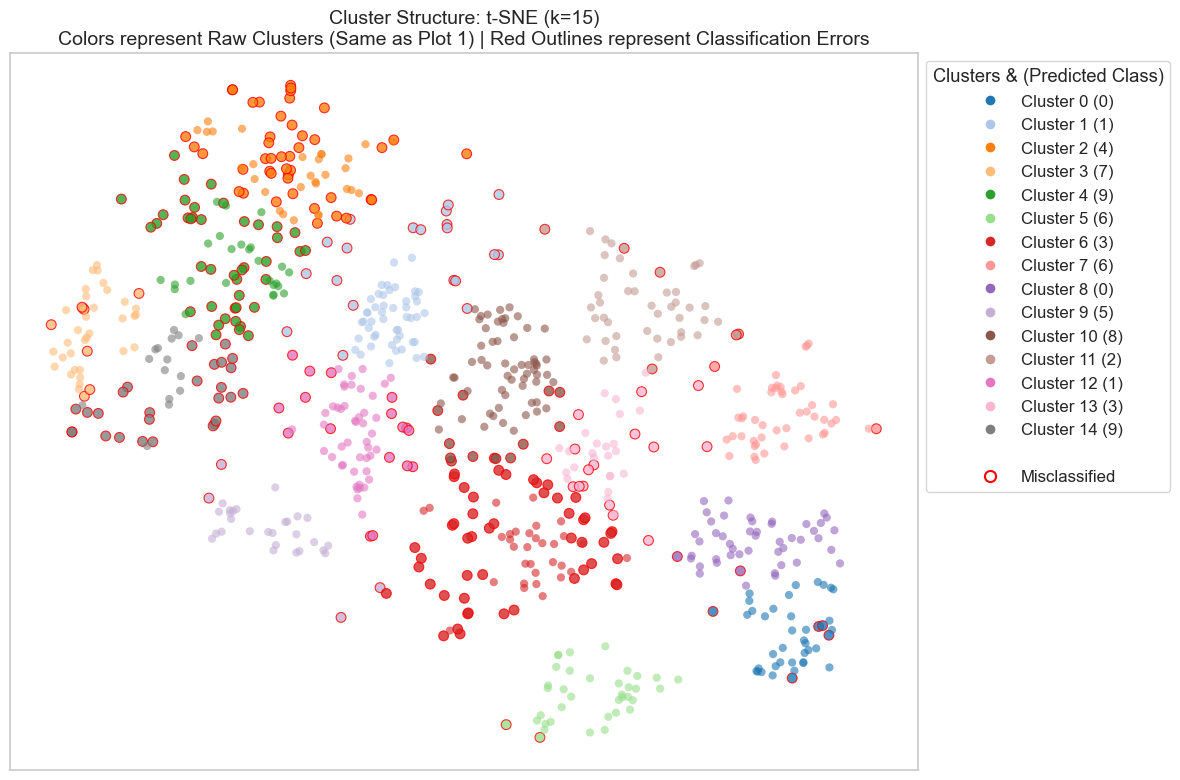

In [7]:
def get_cluster_accuracy(cluster_labels, true_labels):
    mapped_preds = np.zeros_like(cluster_labels)
    # Store the mapping for legend generation later
    cluster_to_class_map = {} 
    
    for cid in np.unique(cluster_labels):
        mask = (cluster_labels == cid)
        if np.sum(mask) == 0: continue
        true_vals = true_labels[mask]
        dominant_label = np.bincount(true_vals).argmax()
        mapped_preds[mask] = dominant_label
        cluster_to_class_map[cid] = dominant_label
        
    return accuracy_score(true_labels, mapped_preds), mapped_preds, cluster_to_class_map

cluster_sizes_to_test = [10, 15, 20, 25, 30]
n_samples = 2000

for dataset_name, (X, y) in datasets.items():
    print(f"Processing {dataset_name}...")
    
    best_model = {"score": -1, "info": None}
    
    # Subsample if necessary
    idx = rng.choice(len(X), n_samples, replace=False) if len(X) > n_samples else np.arange(len(X))
    X_small, y_small = X[idx], y[idx]
    
    X_scaled = StandardScaler().fit_transform(X_small)

    embeddings = {}
    for method in methods_to_compare:
        embeddings[method] = get_embedding(method, X_scaled)

    n_methods = len(methods_to_compare)
    n_k = len(cluster_sizes_to_test)
    
    # PLOT 1: GRID OF CLUSTERS (Original) 
    fig, axes = plt.subplots(n_methods, n_k, figsize=(3 * n_k, 3 * n_methods))
    fig.suptitle(f'{dataset_name}: Clusters Colored by Cluster ID', fontsize=16)
    
    if n_methods == 1: axes = np.expand_dims(axes, 0)
    if n_k == 1: axes = np.expand_dims(axes, 1)

    table_data = []

    for i, method in enumerate(methods_to_compare):
        emb = embeddings[method]
        X_train, X_test, y_train, y_test = train_test_split(emb, y_small, test_size=0.4, random_state=42)
        
        for j, k in enumerate(cluster_sizes_to_test):
            # Cluster
            sc = SpectralClustering(n_clusters=k, affinity='nearest_neighbors', random_state=42, n_jobs=-1)
            train_labels = sc.fit_predict(X_train)
            
            # Predict on Test
            clf = NearestCentroid()
            clf.fit(X_train, train_labels)
            test_labels = clf.predict(X_test)
            
            # Metrics
            ari = adjusted_rand_score(y_test, test_labels)
            acc, mapped_preds, mapping_dict = get_cluster_accuracy(test_labels, y_test)
            
            table_data.append({
                "Method": method, "k": k,
                "ARI": ari, "Acc": acc,
                "NMI": normalized_mutual_info_score(y_test, test_labels),
                "Sil": silhouette_score(X_test, test_labels)
            })
            
            # Save Best Model
            if ari > best_model["score"]:
                best_model = {
                    "score": ari, 
                    "method": method, 
                    "k": k,
                    "y_true": y_test, 
                    "y_pred": mapped_preds,
                    "cluster_labels": test_labels, # The Raw Cluster ID (e.g. 5)
                    "mapping": mapping_dict,     # Dictionary {ClusterID: ClassID}
                    "X_test": X_test  
                }

            # Plot grid
            ax = axes[i, j]
            ax.scatter(X_train[:, 0], X_train[:, 1], c=train_labels, cmap='tab20', alpha=0.6, s=10)
            ax.set_title(f"{method} k={k}\nARI:{ari:.2f} Acc:{acc:.2f}", fontsize=8)
            ax.set_xticks([]); ax.set_yticks([])
            if j == 0: ax.set_ylabel(method)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

    # METRICS TABLE
    df = pd.DataFrame(table_data).sort_values(by="ARI", ascending=False)
    print("\nMetrics Summary (Sorted by ARI):")
    print(df.to_string(index=False, float_format="%.3f"))

    if best_model["score"] > -1:
        bm = best_model
        print(f"\nBest Model: {bm['method']} (k={bm['k']}) | ARI: {bm['score']:.3f}")

        # PLOT 2: CONFUSION MATRIX 
        y_true = bm['y_true']
        y_pred = bm['y_pred']
        cm = confusion_matrix(y_true, y_pred)
        
        unique_labels = np.unique(y_true)
        axis_labels = target_names if target_names is not None else unique_labels

        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                    xticklabels=axis_labels, yticklabels=axis_labels)
        plt.title(f"Confusion Matrix: {bm['method']} (k={bm['k']})")
        plt.xlabel('Predicted Class')
        plt.ylabel('True Class')
        plt.show()

        # PLOT 3: CORRECTNESS VISUALIZATION
        X_best = bm['X_test']
        y_pred = bm['y_pred']          # Mapped classes (for error checking)
        clusters = bm['cluster_labels'] # Raw clusters (for coloring)
        y_true = bm['y_true']
        
        correct_mask = (y_pred == y_true)
        incorrect_mask = ~correct_mask
        acc_best = accuracy_score(y_true, y_pred)

        # Use tab20 to match Plot 1 exactly
        cmap_name = 'tab20'
        cmap = plt.get_cmap(cmap_name)
        
        plt.figure(figsize=(12, 8))
        
        # 1. Plot INCORRECT points (Red Outline, but filled with Cluster Color)
        plt.scatter(
            X_best[incorrect_mask, 0], X_best[incorrect_mask, 1], 
            c=clusters[incorrect_mask],  
            cmap=cmap_name, 
            vmin=0, vmax=19, # Consistent range for tab20
            s=50, 
            alpha=0.8, 
            linewidths=0.8,      
            edgecolors='red',    
            label='_nolegend_'
        )

        # 2. Plot CORRECT points
        plt.scatter(
            X_best[correct_mask, 0], X_best[correct_mask, 1], 
            c=clusters[correct_mask],   
            cmap=cmap_name, 
            vmin=0, vmax=19,
            s=35, 
            alpha=0.6, 
            edgecolors='none',
            label='_nolegend_'
        )

        plt.title(f"Cluster Structure: {bm['method']} (k={bm['k']})\n"
                  f"Colors represent Raw Clusters (Same as Plot 1) | Red Outlines represent Classification Errors", 
                  fontsize=14)
        
        # LEGEND GENERATION (PER CLUSTER) 
        legend_elements = []
        mapping = bm['mapping']
        
        # Loop through every CLUSTER (0 to k-1)
        for cid in range(bm['k']):
            # Get the color for this cluster ID
            color = cmap(cid / 19.0) if cid < 20 else 'gray'
            
            # Determine what this cluster "voted" for
            if cid in mapping:
                pred_class_id = mapping[cid]
                if dataset_name == 'CIFAR-10':
                    class_name = target_names[pred_class_id]
                else:
                    class_name = str(pred_class_id)
                label_text = f"Cluster {cid} ({class_name})"
            else:
                label_text = f"Cluster {cid} (Empty)"

            legend_elements.append(
                Line2D([0], [0], marker='o', color='w', label=label_text,
                       markerfacecolor=color, markersize=8)
            )

        # Add Error Indicator
        legend_elements.append(Line2D([0], [0], color='none', label=' '))
        legend_elements.append(
            Line2D([0], [0], marker='o', color='w', label='Misclassified',
                   markerfacecolor='none', markeredgecolor='red', 
                   markeredgewidth=1.5, markersize=8)
        )

        plt.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1, 1), 
                   title="Clusters & (Predicted Class)", frameon=True)
        
        plt.xticks([]); plt.yticks([])
        plt.tight_layout()
        plt.show()

## 5. Feature Comparison: Raw Pixels vs Learned Representations

In this section, we compare dimensionality reduction on two different input representations:
1. **Raw Pixels**: Direct flattened image data (high-dimensional, noisy)
2. **Foundational Features**: Feature vectors extracted from pretrained CNN backbones:
   - **ResNet-18**: Lightweight model extracting 512-dimensional features (fast, memory-efficient)
   - **ResNet-50**: Deeper model extracting 2048-dimensional features (superior feature quality)

Using features learned by neural networks typically leads to significantly better cluster separability because the models have learned rich, hierarchical representations. By comparing both ResNet-18 (efficiency-focused) and ResNet-50 (quality-focused), we can explore the trade-off between computational cost and representation quality. We compare embeddings computed on both raw pixels and learned features to demonstrate the importance of representation learning.

In [8]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Load pretrained models: ResNet-18 (lightweight) and ResNet-50 (more powerful)
import torch.nn.functional as F 
from torchvision.models import resnet18, resnet50, ResNet18_Weights, ResNet50_Weights

# ResNet-18: 512-dimensional features
weights_18 = ResNet18_Weights.DEFAULT
base_18 = resnet18(weights=weights_18)
backbone_18 = torch.nn.Sequential(*list(base_18.children())[:-1]).to(device)
backbone_18.eval()

# ResNet-50: 2048-dimensional features
weights_50 = ResNet50_Weights.DEFAULT
base_50 = resnet50(weights=weights_50)
backbone_50 = torch.nn.Sequential(*list(base_50.children())[:-1]).to(device)
backbone_50.eval()

# Handles flattened CIFAR (3072) and MNIST (784) formats
def images_from_flat(X):
    X = np.asarray(X)
    if X.shape[1] == 3072:  # CIFAR (3 * 32 * 32)
        imgs = X.reshape(-1, 3, 32, 32)
    elif X.shape[1] == 784:  # MNIST (1 * 28 * 28) — replicate channels to make it 3
        imgs = X.reshape(-1, 1, 28, 28)
        imgs = np.repeat(imgs, 3, axis=1)
    return imgs

def extract_features(imgs, backbone, batch_size=256):
    imgs = images_from_flat(imgs)
    imgs_t = torch.tensor(imgs, dtype=torch.float32)
    N = imgs_t.shape[0]

    #min-max scaling to [0,1]
    mins = imgs_t.view(N, -1).min(dim=1)[0].view(N, 1, 1, 1)
    maxs = imgs_t.view(N, -1).max(dim=1)[0].view(N, 1, 1, 1)
    denom = (maxs - mins)
    denom[denom < 1e-6] = 1.0
    imgs_t = (imgs_t - mins) / denom

    # Resize to ResNet's expected size (224x224). Doing this in-tensor is efficient on GPU.
    imgs_t = F.interpolate(imgs_t.to(device), size=(224, 224), mode='bilinear', align_corners=False)

    # Normalize using ImageNet mean/std so the pretrained weights behave well.
    mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
    imgs_t = (imgs_t - mean) / std

    feats = []
    with torch.no_grad():
        for i in range(0, N, batch_size):
            batch = imgs_t[i:i+batch_size]
            out = backbone(batch)
            out = out.reshape(out.shape[0], -1)
            feats.append(out.cpu().numpy())
    feats = np.vstack(feats)
    return feats

# Run feature extraction for each dataset with both models
foundational_features = {}
foundational_labels = {}

for name, (X, y) in datasets.items():
    print(f"\nProcessing dataset: {name} | shape: {X.shape}")
    
    # Extract features using ResNet-18
    print(f"  Extracting features with ResNet-18 (512-dim)...")
    feats_18 = extract_features(X, backbone_18, batch_size=256)
    
    # Extract features using ResNet-50
    print(f"  Extracting features with ResNet-50 (2048-dim)...")
    feats_50 = extract_features(X, backbone_50, batch_size=256)
    
    foundational_features[name] = {'ResNet-18': feats_18, 'ResNet-50': feats_50}
    foundational_labels[name] = y
    print(f"  ResNet-18 features shape: {feats_18.shape}")
    print(f"  ResNet-50 features shape: {feats_50.shape}")

print(f"\nFeature extraction complete with both ResNet-18 (512-dim) and ResNet-50 (2048-dim)")

Using device: cpu

Processing dataset: CIFAR-10 | shape: (2000, 3072)
  Extracting features with ResNet-18 (512-dim)...
  Extracting features with ResNet-50 (2048-dim)...
  ResNet-18 features shape: (2000, 512)
  ResNet-50 features shape: (2000, 2048)

Processing dataset: MNIST | shape: (2000, 784)
  Extracting features with ResNet-18 (512-dim)...
  Extracting features with ResNet-50 (2048-dim)...
  ResNet-18 features shape: (2000, 512)
  ResNet-50 features shape: (2000, 2048)

Feature extraction complete with both ResNet-18 (512-dim) and ResNet-50 (2048-dim)



Processing: Raw Pixels

Dataset: CIFAR-10 | shape: (2000, 3072)
Computing embeddings...
Using Spectral Embedding from Scratch
Using Spectral Embedding from scikit-learn
Using Isomap from scikit-learn
Using t-SNE from scikit-learn


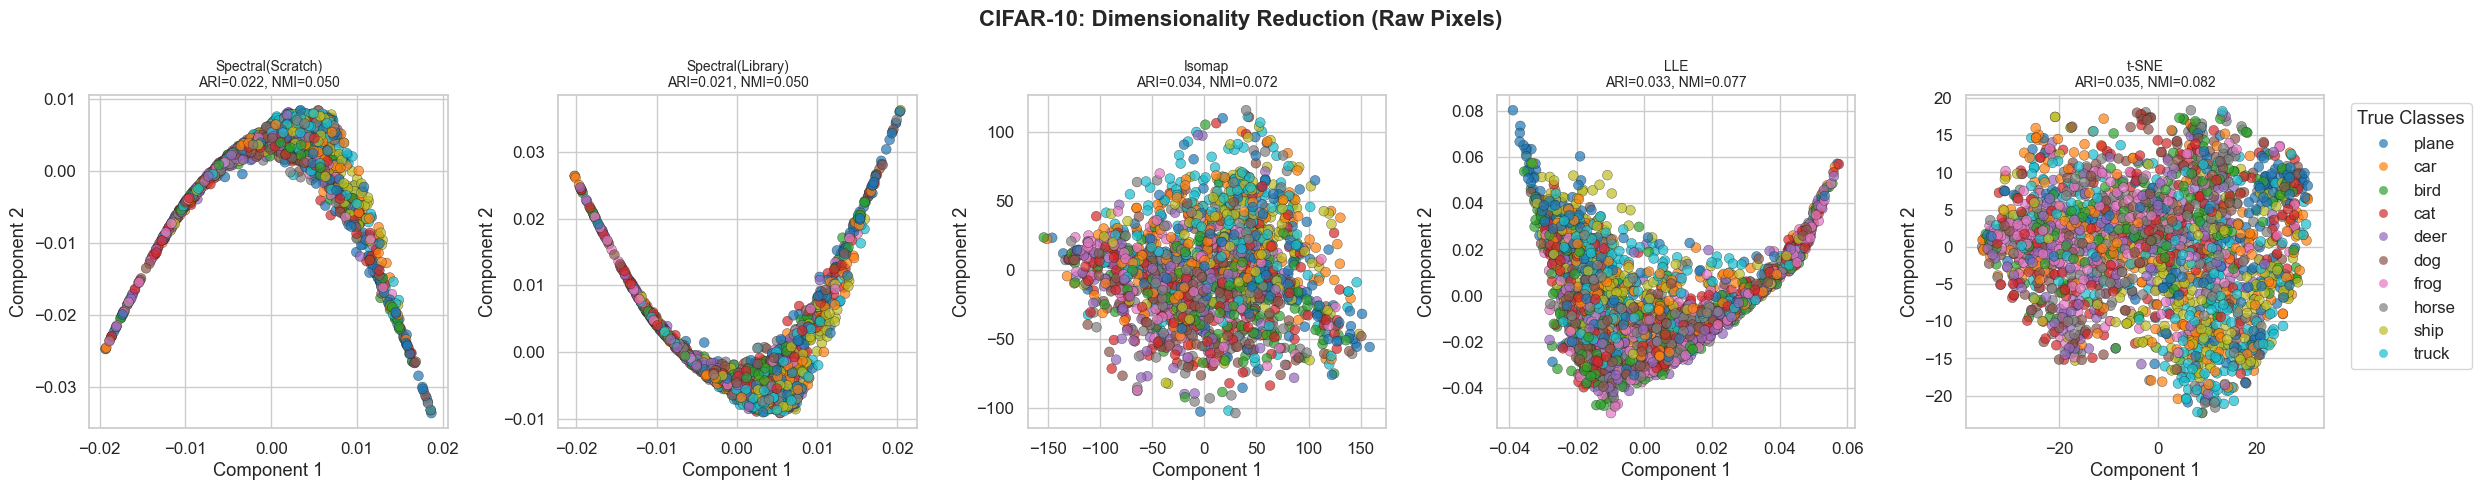

Saved figure to: figures\cifar-10_raw_pixels_embeddings.png

Metrics Summary for CIFAR-10 (Raw Pixels):
           Method      ARI      NMI
            t-SNE 0.034532 0.081729
           Isomap 0.034388 0.072383
              LLE 0.032985 0.076908
Spectral(Scratch) 0.021886 0.049970
Spectral(Library) 0.021265 0.050487

Dataset: MNIST | shape: (2000, 784)
Computing embeddings...
Using Spectral Embedding from Scratch
Using Spectral Embedding from scikit-learn
Using Isomap from scikit-learn
Using t-SNE from scikit-learn


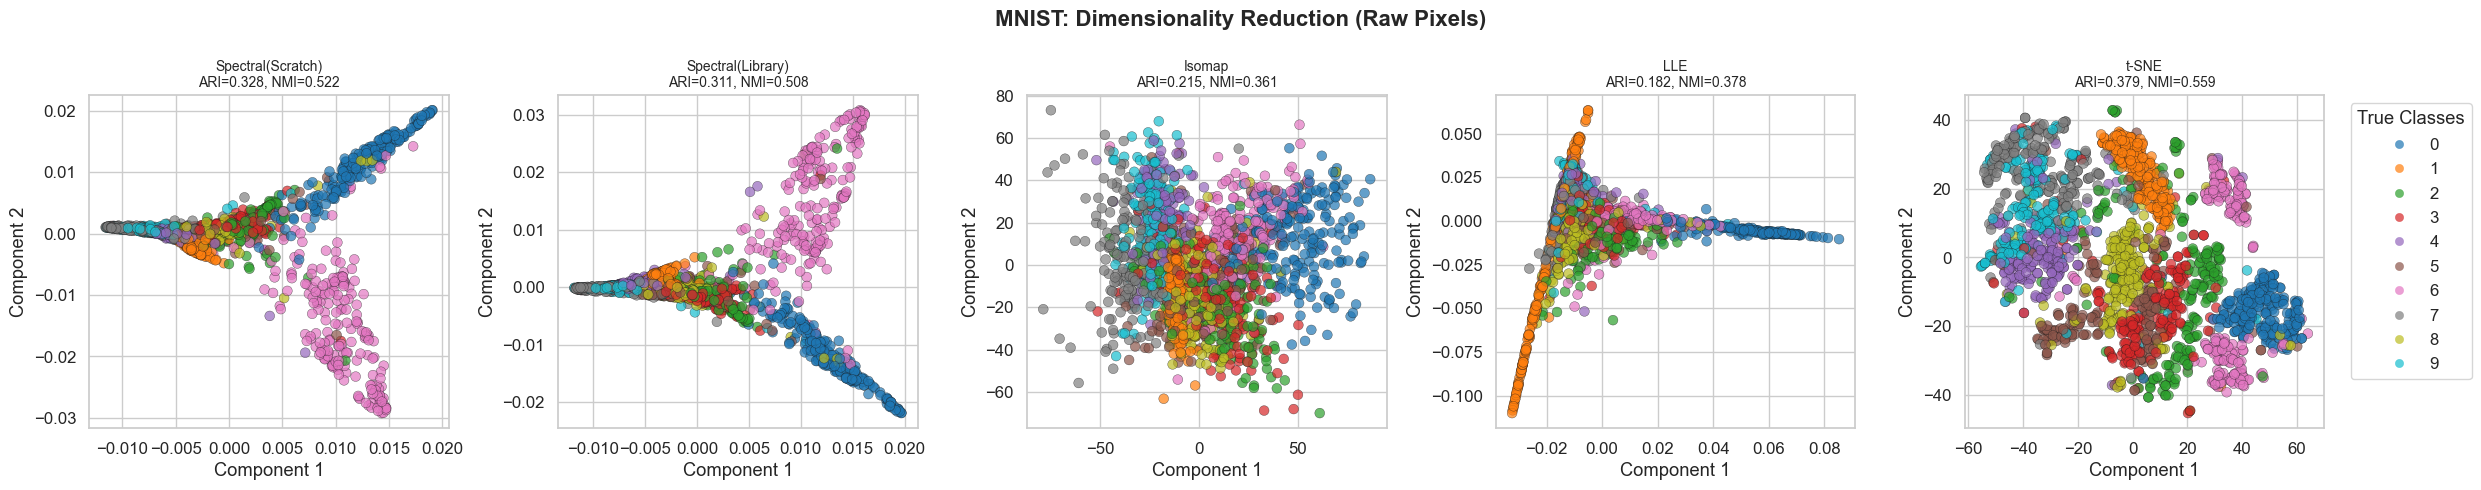

Saved figure to: figures\mnist_raw_pixels_embeddings.png

Metrics Summary for MNIST (Raw Pixels):
           Method      ARI      NMI
            t-SNE 0.378742 0.559184
Spectral(Scratch) 0.327804 0.522119
Spectral(Library) 0.311291 0.508173
           Isomap 0.214716 0.361020
              LLE 0.182388 0.378104

Processing: ResNet-18 Features (512-dim)

Dataset: CIFAR-10 | shape: (2000, 512)
Computing embeddings...
Using Spectral Embedding from Scratch
Using Spectral Embedding from scikit-learn
Using Isomap from scikit-learn
Using t-SNE from scikit-learn


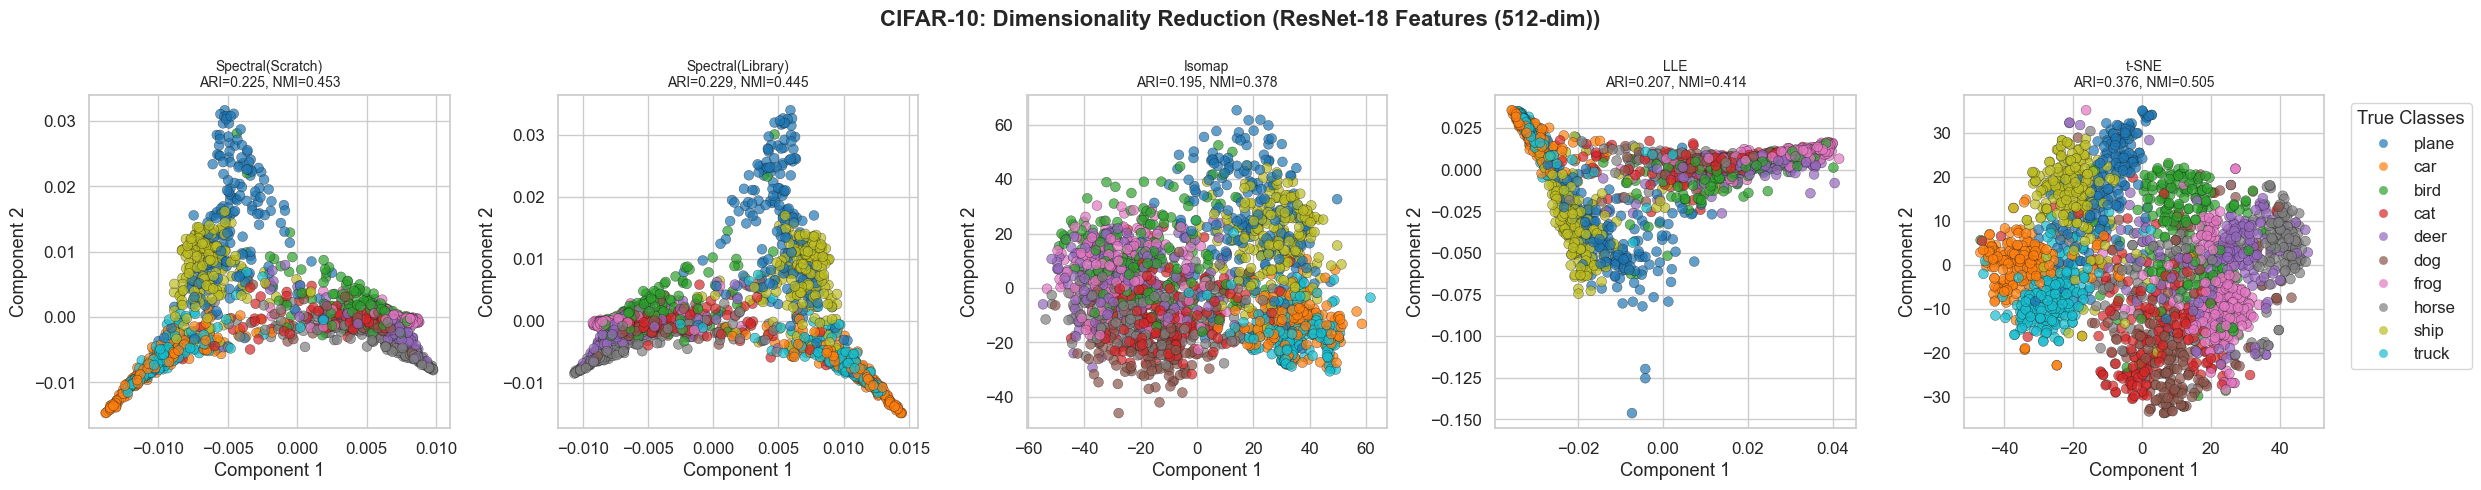

Saved figure to: figures\cifar-10_resnet_18_features_512_dim_embeddings.png

Metrics Summary for CIFAR-10 (ResNet-18 Features (512-dim)):
           Method      ARI      NMI
            t-SNE 0.375788 0.504865
Spectral(Library) 0.228772 0.444944
Spectral(Scratch) 0.224511 0.452968
              LLE 0.207281 0.414425
           Isomap 0.194994 0.378042

Dataset: MNIST | shape: (2000, 512)
Computing embeddings...
Using Spectral Embedding from Scratch
Using Spectral Embedding from scikit-learn
Using Isomap from scikit-learn
Using t-SNE from scikit-learn


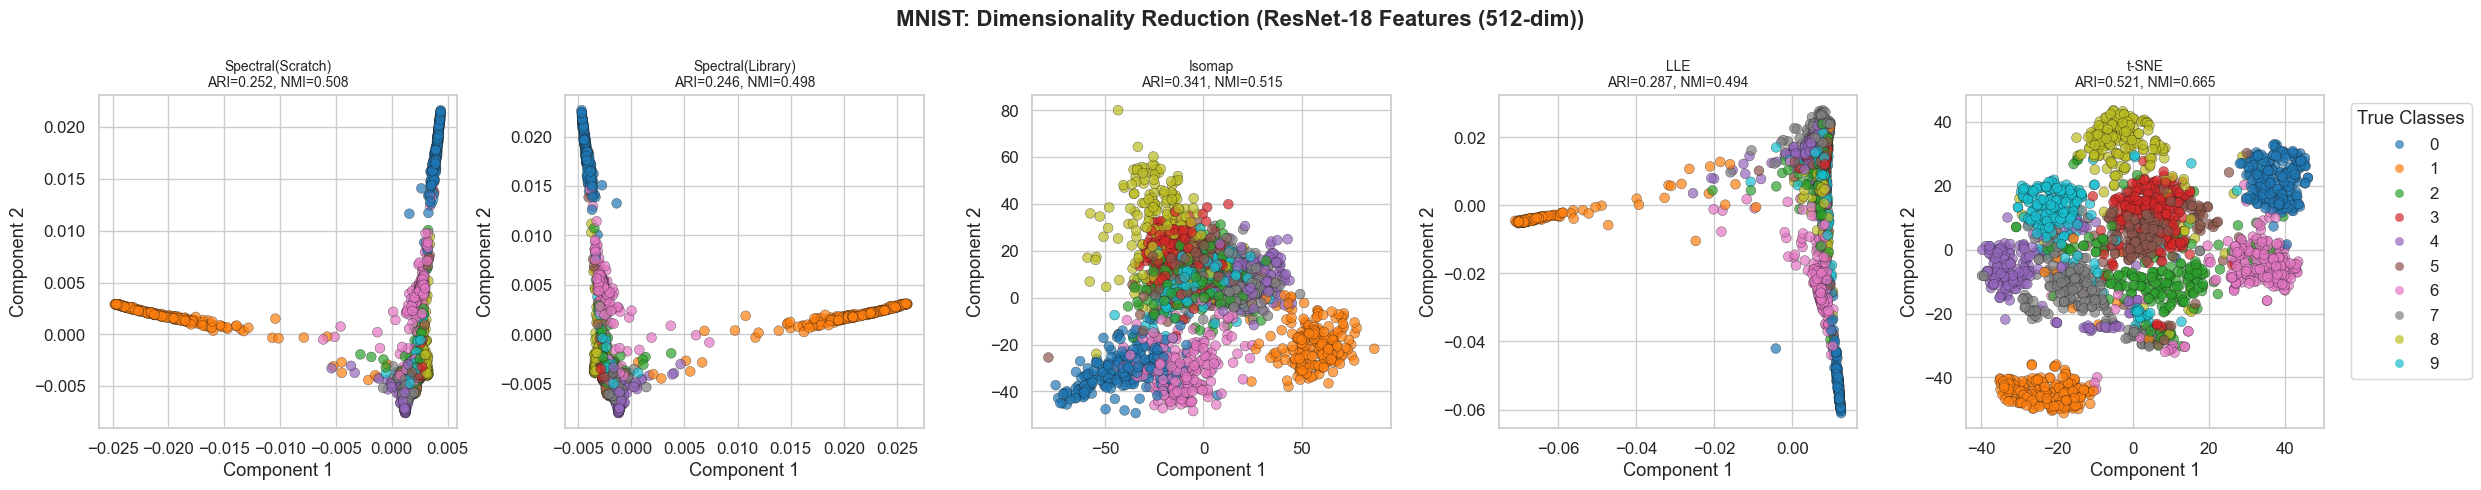

Saved figure to: figures\mnist_resnet_18_features_512_dim_embeddings.png

Metrics Summary for MNIST (ResNet-18 Features (512-dim)):
           Method      ARI      NMI
            t-SNE 0.521215 0.665075
           Isomap 0.341133 0.514634
              LLE 0.286708 0.494464
Spectral(Scratch) 0.251667 0.508452
Spectral(Library) 0.245784 0.497866

Processing: ResNet-50 Features (2048-dim)

Dataset: CIFAR-10 | shape: (2000, 2048)
Computing embeddings...
Using Spectral Embedding from Scratch
Using Spectral Embedding from scikit-learn
Using Isomap from scikit-learn
Using t-SNE from scikit-learn


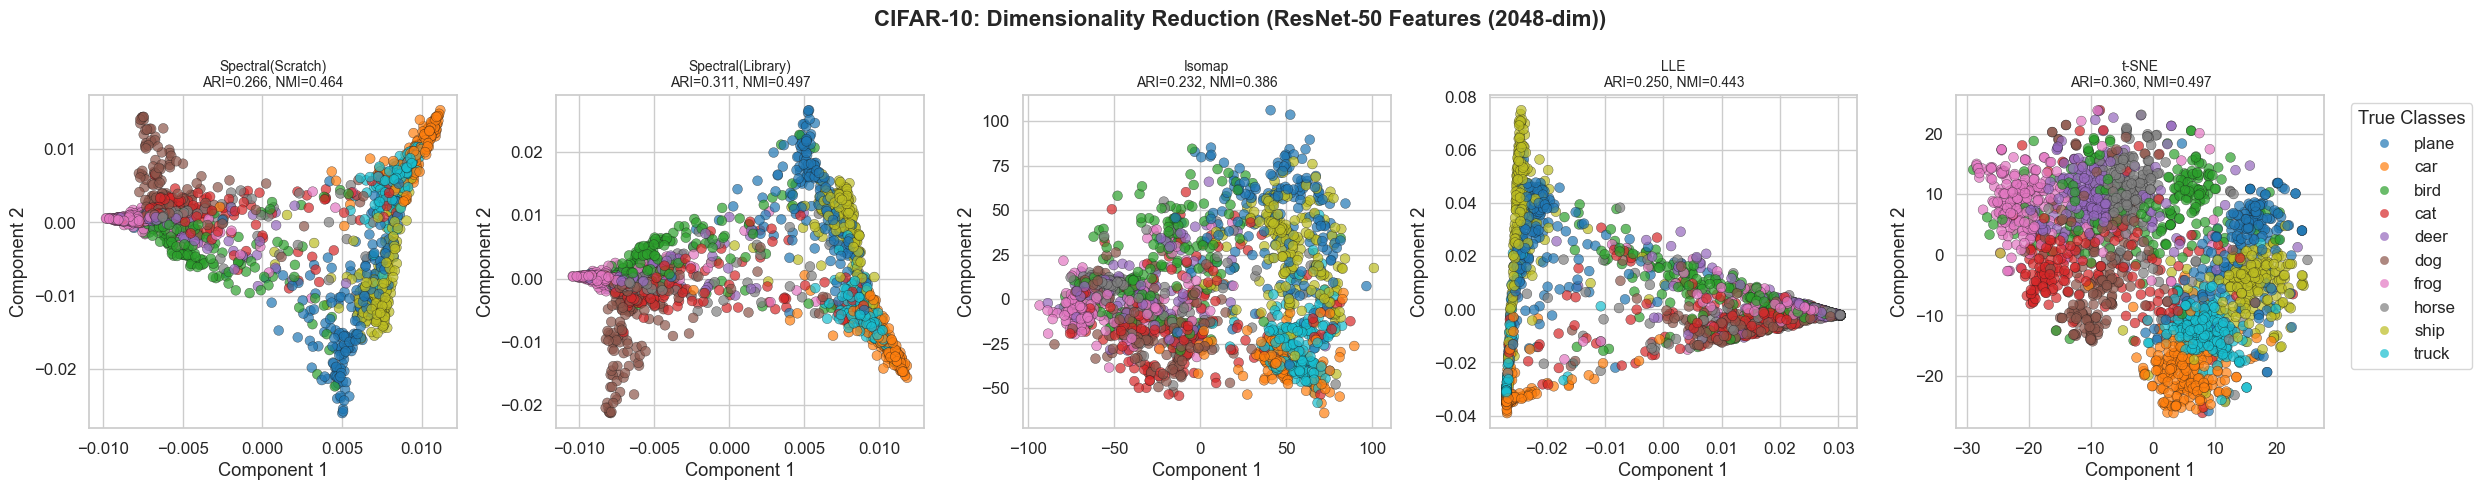

Saved figure to: figures\cifar-10_resnet_50_features_2048_dim_embeddings.png

Metrics Summary for CIFAR-10 (ResNet-50 Features (2048-dim)):
           Method      ARI      NMI
            t-SNE 0.360048 0.496586
Spectral(Library) 0.311192 0.497303
Spectral(Scratch) 0.265724 0.464350
              LLE 0.250420 0.442942
           Isomap 0.232174 0.385939

Dataset: MNIST | shape: (2000, 2048)
Computing embeddings...
Using Spectral Embedding from Scratch
Using Spectral Embedding from scikit-learn
Using Isomap from scikit-learn
Using t-SNE from scikit-learn


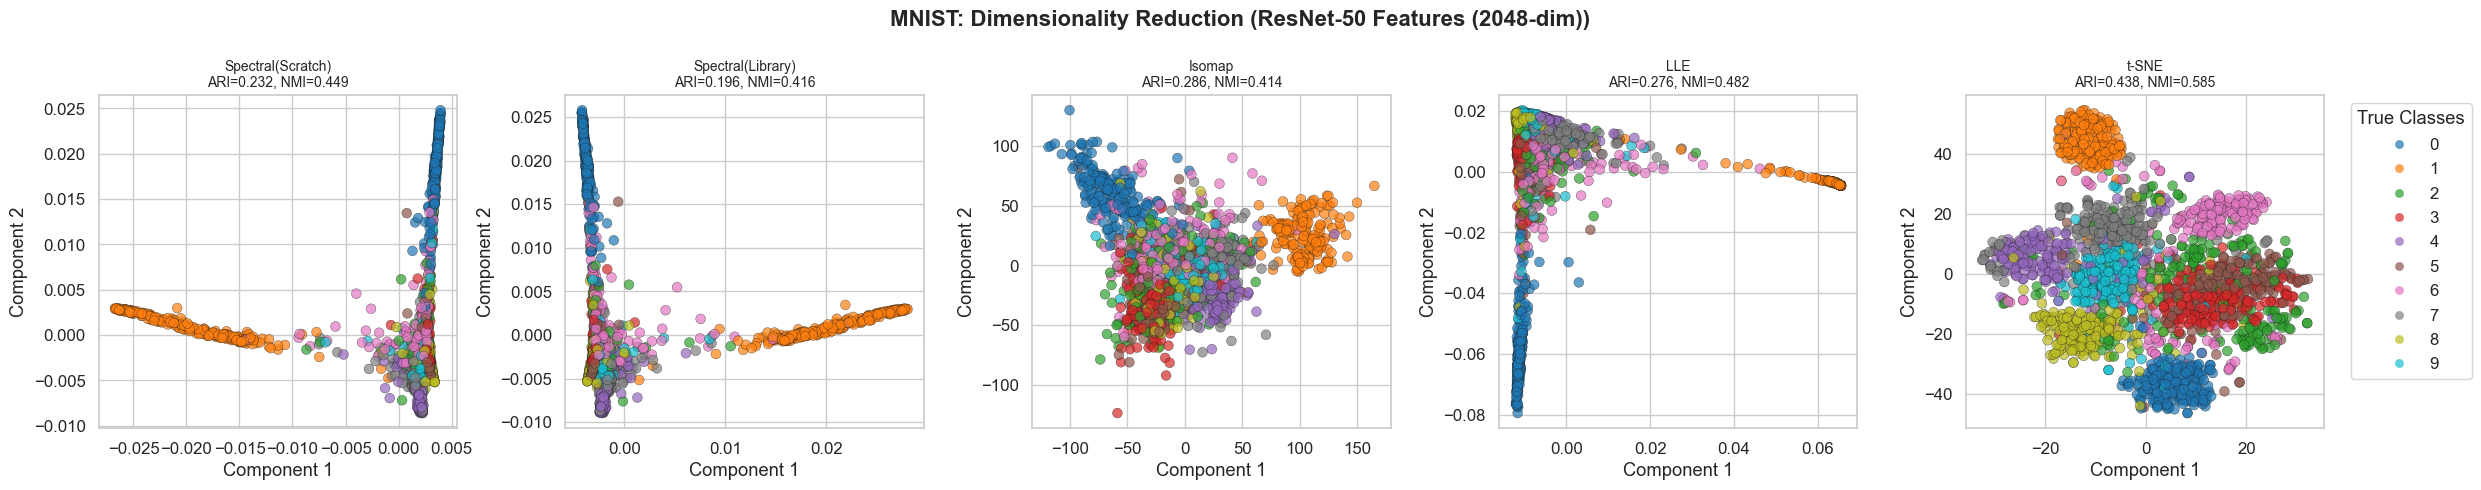

Saved figure to: figures\mnist_resnet_50_features_2048_dim_embeddings.png

Metrics Summary for MNIST (ResNet-50 Features (2048-dim)):
           Method      ARI      NMI
            t-SNE 0.438356 0.584522
           Isomap 0.286161 0.413668
              LLE 0.276195 0.481954
Spectral(Scratch) 0.232158 0.448784
Spectral(Library) 0.196333 0.415934


In [9]:
# Compare dimensionality reduction on Raw Pixels vs Foundational Features (ResNet-18 and ResNet-50)
methods_to_compare = ['Spectral(Scratch)', 'Spectral(Library)', 'Isomap', 'LLE', 't-SNE']

# Helper to coerce inputs to numpy arrays
def to_numpy(x):
    if isinstance(x, np.ndarray):
        return x
    if isinstance(x, list):
        return np.asarray(x)
    if 'torch' in str(type(x)):
        return x.cpu().numpy()
    return np.asarray(x)

rng = np.random.default_rng(42)

# Process both raw pixel data and foundational features from both ResNet models
data_sources = [
    ('Raw Pixels', datasets),
    ('ResNet-18 Features (512-dim)', {'CIFAR-10': (foundational_features['CIFAR-10']['ResNet-18'], foundational_labels['CIFAR-10']),
                                       'MNIST': (foundational_features['MNIST']['ResNet-18'], foundational_labels['MNIST'])}),
    ('ResNet-50 Features (2048-dim)', {'CIFAR-10': (foundational_features['CIFAR-10']['ResNet-50'], foundational_labels['CIFAR-10']),
                                        'MNIST': (foundational_features['MNIST']['ResNet-50'], foundational_labels['MNIST'])})
]

for source_name, data_dict in data_sources:
    print(f"\n{'='*60}")
    print(f"Processing: {source_name}")
    print(f"{'='*60}")

    for dataset_name, (X, y) in data_dict.items():
        X = to_numpy(X)
        y = to_numpy(y)

        print(f"\nDataset: {dataset_name} | shape: {X.shape}")

        # Subsample for faster processing
        n_samples = min(2000, len(X))
        indices = rng.choice(len(X), n_samples, replace=False)
        X_small = X[indices]
        y_small = y[indices]

        # Standardize
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X_small)

        # Get embeddings for all methods
        embeddings = {}
        print(f"Computing embeddings...")
        for method in methods_to_compare:
            emb = get_embedding(method, X_scaled, n_components=2)
            embeddings[method] = emb

        # Create 1x5 grid comparison plot
        fig, axes = plt.subplots(1, 5, figsize=(25, 5))
        fig.suptitle(f'{dataset_name}: Dimensionality Reduction ({source_name})', fontsize=16, fontweight='bold')

        metrics_data = []

        for i, method in enumerate(methods_to_compare):
            ax = axes[i]
            emb = embeddings[method]

            # Apply Spectral Clustering on the 2D embeddings for comparison
            try:
                sc = SpectralClustering(n_clusters=10, affinity='nearest_neighbors', random_state=42, n_jobs=-1)
                cluster_labels = sc.fit_predict(emb)

                # Calculate metrics
                ari = adjusted_rand_score(y_small, cluster_labels)
                nmi = normalized_mutual_info_score(y_small, cluster_labels)

                metrics_data.append({'Method': method, 'ARI': ari, 'NMI': nmi})

                # Plot colored by true labels
                scatter = ax.scatter(emb[:, 0], emb[:, 1], c=y_small, cmap='tab10', alpha=0.7, s=50, edgecolors='k', linewidth=0.3)
                ax.set_title(f'{method}\nARI={ari:.3f}, NMI={nmi:.3f}', fontsize=10)
                ax.set_xlabel('Component 1')
                ax.set_ylabel('Component 2')

            except Exception as e:
                ax.text(0.5, 0.5, f'{method}\nClustering failed', ha='center', va='center', transform=ax.transAxes)
                ax.set_title(f'{method} - ERROR')

        # Add legend
        if dataset_name == 'CIFAR-10':
            handles, _ = scatter.legend_elements(prop="colors")
            plt.legend(handles, target_names, title="True Classes", bbox_to_anchor=(1.05, 1), loc='upper left')
        else:
            plt.legend(*scatter.legend_elements(), title="True Classes", bbox_to_anchor=(1.05, 1), loc='upper left')

        plt.tight_layout()
        plt.show()
        os.makedirs('figures', exist_ok=True)
        source_clean = source_name.lower().replace(' ', '_').replace('(', '').replace(')', '').replace('-', '_')
        fig_path = os.path.join('figures', f'{dataset_name.lower()}_{source_clean}_embeddings.png')
        fig.savefig(fig_path, dpi=200, bbox_inches='tight')
        print(f"Saved figure to: {fig_path}")
        # Print metrics table
        if metrics_data:
            df_metrics = pd.DataFrame(metrics_data).sort_values(by='ARI', ascending=False)
            print(f"\nMetrics Summary for {dataset_name} ({source_name}):")
            print(df_metrics.to_string(index=False))





=== Processing Dataset: CIFAR-10 (aggregating all sources & embeddings) ===
Using Spectral Embedding from Scratch
Using Spectral Embedding from scikit-learn
Using Isomap from scikit-learn
Using t-SNE from scikit-learn
Using Spectral Embedding from Scratch
Using Spectral Embedding from scikit-learn
Using Isomap from scikit-learn
Using t-SNE from scikit-learn
Using Spectral Embedding from Scratch
Using Spectral Embedding from scikit-learn
Using Isomap from scikit-learn
Using t-SNE from scikit-learn

Top results for CIFAR-10 (aggregated across all sources and embeddings):
                       Source  Dataset            Method  k   ARI   Acc   NMI   Sil
 ResNet-18 Features (512-dim) CIFAR-10             t-SNE 10 0.446 0.634 0.549 0.366
ResNet-50 Features (2048-dim) CIFAR-10             t-SNE 10 0.441 0.662 0.538 0.370
ResNet-50 Features (2048-dim) CIFAR-10             t-SNE 15 0.346 0.646 0.512 0.340
 ResNet-18 Features (512-dim) CIFAR-10             t-SNE 15 0.332 0.619 0.509 0.317
Res

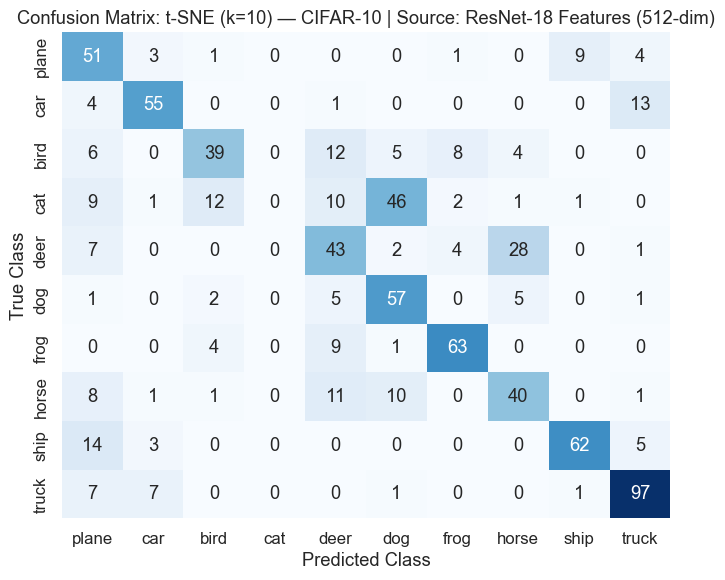

  Saved cluster visualization to: figures\cifar-10_best_t-SNE_ResNet-18_Features_(512-dim)_k10.png


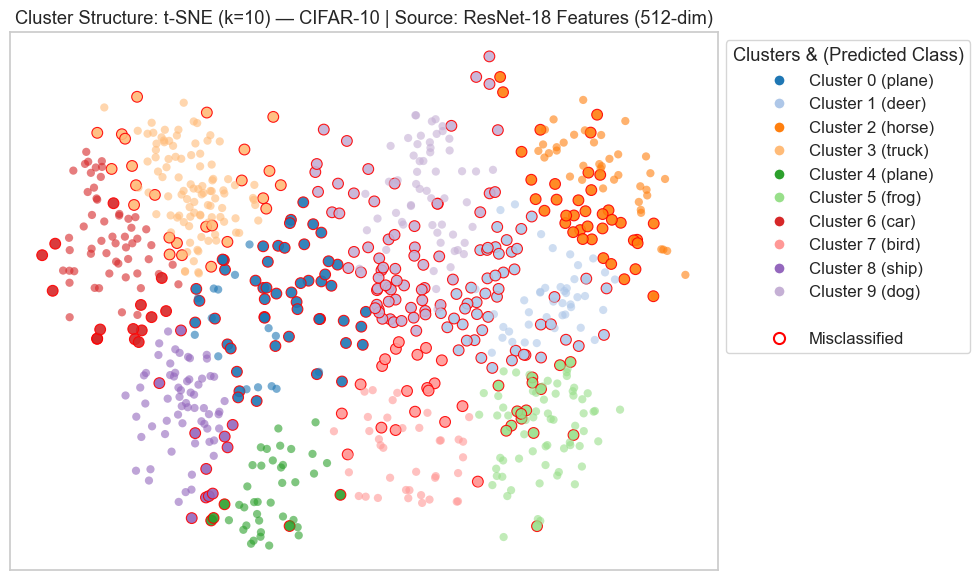

  Saved confusion matrix to: figures\mnist_best_confusion_t-SNE_ResNet-18_Features_(512-dim)_k10.png


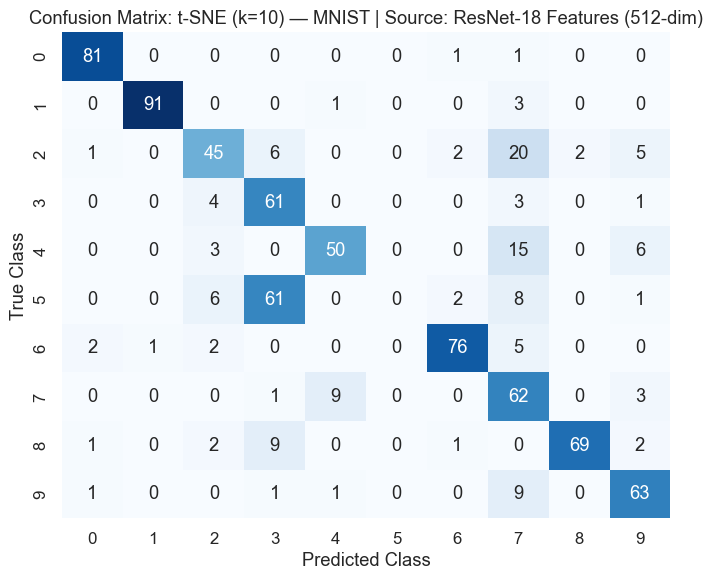

  Saved cluster visualization to: figures\mnist_best_t-SNE_ResNet-18_Features_(512-dim)_k10.png


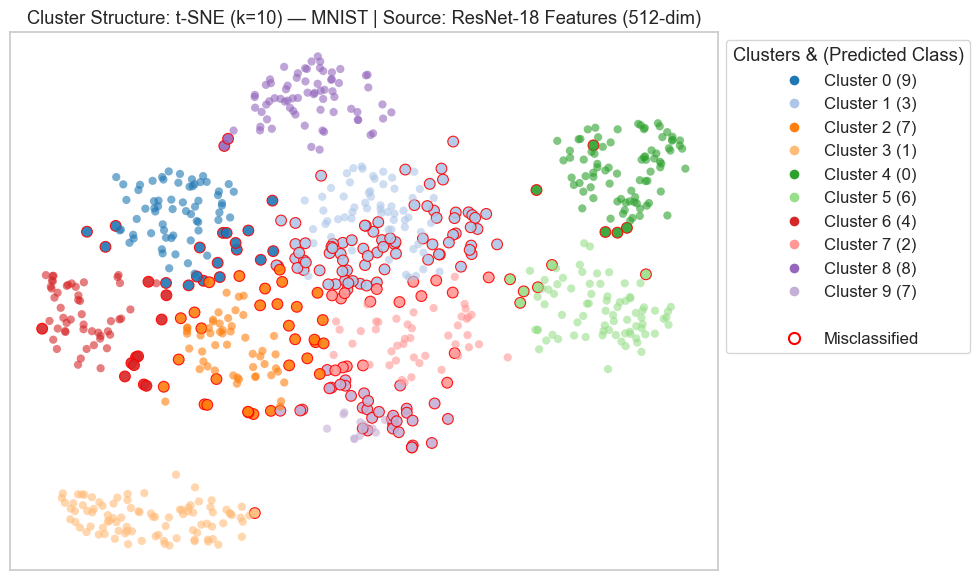

In [ ]:
cluster_sizes_to_test = [10, 15, 20, 25, 30]
n_samples = 2000

# Primary metric to choose best model (change to 'Acc' or 'NMI' if you prefer)
BEST_METRIC = 'ARI'

results = []  # collect per-run metrics across all datasets/sources/methods
artifacts = {}  # store artifacts for later plotting keyed by (Dataset, Source, Method, k)

# Ensure helper to coerce to numpy exists
try:
    to_numpy
except NameError:
    def to_numpy(x):
        if isinstance(x, np.ndarray):
            return x
        if isinstance(x, list):
            return np.asarray(x)
        if 'torch' in str(type(x)):
            return x.cpu().numpy()
        return np.asarray(x)

# Evaluate per DATASET, aggregating results from all SOURCES and METHODS
for dataset_name in ['CIFAR-10', 'MNIST']:
    print(f"\n=== Processing Dataset: {dataset_name} (aggregating all sources & embeddings) ===")

    table_data = []

    for source_name, data_dict in data_sources:
        # Each data_dict maps dataset names to (X, y)
        if dataset_name not in data_dict:
            continue
        X_full, y_full = data_dict[dataset_name]
        X_full = to_numpy(X_full)
        y_full = to_numpy(y_full)

        # Subsample for speed
        idx = rng.choice(len(X_full), n_samples, replace=False) if len(X_full) > n_samples else np.arange(len(X_full))
        X_small, y_small = X_full[idx], y_full[idx]

        # Standardize so embeddings are comparable
        X_scaled = StandardScaler().fit_transform(X_small)

        # Precompute embeddings for this source
        embeddings = {}
        for method in methods_to_compare:
            try:
                emb = get_embedding(method, X_scaled, n_components=2)
                embeddings[method] = emb
            except Exception as e:
                print(f"  Warning: embedding {method} failed for {dataset_name} ({source_name}): {e}")
                embeddings[method] = None

        # For each method and cluster size, run clustering and collect metrics
        for method, emb in embeddings.items():
            if emb is None:
                continue

            X_train, X_test, y_train, y_test = train_test_split(emb, y_small, test_size=0.4, random_state=42)

            for k in cluster_sizes_to_test:
                try:
                    sc = SpectralClustering(n_clusters=k, affinity='nearest_neighbors', random_state=42, n_jobs=-1)
                    train_labels = sc.fit_predict(X_train)

                    clf = NearestCentroid()
                    clf.fit(X_train, train_labels)
                    test_cluster_labels = clf.predict(X_test)

                    # Metrics
                    ari = adjusted_rand_score(y_test, test_cluster_labels)
                    acc, mapped_preds, mapping_dict = get_cluster_accuracy(test_cluster_labels, y_test)
                    nmi = normalized_mutual_info_score(y_test, test_cluster_labels)
                    sil = np.nan
                    if len(np.unique(test_cluster_labels)) > 1:
                        sil = silhouette_score(X_test, test_cluster_labels)

                    row = {
                        'Source': source_name,
                        'Dataset': dataset_name,
                        'Method': method,
                        'k': k,
                        'ARI': ari,
                        'Acc': acc,
                        'NMI': nmi,
                        'Sil': sil
                    }
                    table_data.append(row)
                    results.append(row)

                    # Save artifacts keyed by dataset-first tuple
                    artifacts[(dataset_name, source_name, method, k)] = {
                        'y_true': y_test.copy(),
                        'y_pred': mapped_preds.copy(),
                        'cluster_labels': test_cluster_labels.copy(),
                        'mapping': mapping_dict.copy(),
                        'X_test': X_test.copy(),
                        'k': k,
                        'source': source_name
                    }

                except Exception as e:
                    print(f"  Warning: Clustering failed for {dataset_name} | {method} | {source_name} k={k} -> {e}")
                    continue

    # After aggregating across all sources for this dataset, print a combined top-results table
    if table_data:
        df_ds = pd.DataFrame(table_data).sort_values(by=BEST_METRIC, ascending=False)
        print(f"\nTop results for {dataset_name} (aggregated across all sources and embeddings):")
        print(df_ds.head(20).to_string(index=False, float_format="%.3f"))

# After processing all datasets, save aggregated results and select winners
if results:
    df_all = pd.DataFrame(results)
    print('\n\n=== Aggregated Top Results Across All Sources/Datasets ===')
    print(df_all.sort_values(by=[BEST_METRIC], ascending=False).head(20).to_string(index=False, float_format="%.3f"))

    os.makedirs('results', exist_ok=True)
    df_all.to_csv(os.path.join('results', 'embedding_clustering_evaluation.csv'), index=False)

    # Choose winners per dataset and overall with tie-breakers
    sort_keys = [BEST_METRIC, 'NMI', 'Acc', 'Sil']
    df_sorted = df_all.sort_values(by=sort_keys, ascending=False)

    best_per_dataset = df_sorted.groupby('Dataset', as_index=False).first()
    print('\nBest model per dataset (primary metric then NMI/Acc/Sil):')
    print(best_per_dataset[['Dataset','Source','Method','k','ARI','NMI','Acc','Sil']].to_string(index=False, float_format='%.3f'))

    best_overall = df_sorted.iloc[0]
    print('\nBest overall model:')
    print(best_overall[['Source','Dataset','Method','k','ARI','NMI','Acc','Sil']].to_string())

    # Plot only the overall best model for each Dataset (across all Sources)
    print('\nPlotting only the overall best model for each dataset...')
    os.makedirs('figures', exist_ok=True)

    for _, best in best_per_dataset.iterrows():
        ds = best['Dataset']
        src = best['Source']
        method = best['Method']
        k = int(best['k'])
        key = (ds, src, method, k)

        if key not in artifacts:
            print(f"  Warning: No artifacts found for {ds} | {src} | {method} k={k}")
            continue

        art = artifacts[key]
        y_true = art['y_true']
        y_pred = art['y_pred']
        X_best = art['X_test']
        clusters = art['cluster_labels']
        mapping = art.get('mapping', {})

        # Confusion matrix
        cm = confusion_matrix(y_true, y_pred)
        axis_labels = target_names if ds == 'CIFAR-10' else np.unique(y_true)

        plt.figure(figsize=(7, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                    xticklabels=axis_labels, yticklabels=axis_labels)
        plt.title(f"Confusion Matrix: {method} (k={k}) — {ds} | Source: {src}")
        plt.xlabel('Predicted Class')
        plt.ylabel('True Class')
        fig_path_cm = os.path.join('figures', f"{ds.lower().replace(' ', '_')}_best_confusion_{method.replace(' ', '_')}_{src.replace(' ', '_')}_k{k}.png")
        plt.tight_layout()
        plt.savefig(fig_path_cm, dpi=200, bbox_inches='tight')
        print(f"  Saved confusion matrix to: {fig_path_cm}")
        plt.show()

        # Cluster correctness visualization
        correct_mask = (y_pred == y_true)
        incorrect_mask = ~correct_mask

        cmap_name = 'tab20'
        cmap = plt.get_cmap(cmap_name)

        plt.figure(figsize=(10, 6))
        if np.any(incorrect_mask):
            plt.scatter(X_best[incorrect_mask, 0], X_best[incorrect_mask, 1],
                        c=clusters[incorrect_mask], cmap=cmap_name, vmin=0, vmax=19,
                        s=60, alpha=0.9, linewidths=0.8, edgecolors='red')
        plt.scatter(X_best[correct_mask, 0], X_best[correct_mask, 1],
                    c=clusters[correct_mask], cmap=cmap_name, vmin=0, vmax=19,
                    s=35, alpha=0.6, edgecolors='none')

        plt.title(f"Cluster Structure: {method} (k={k}) — {ds} | Source: {src}")

        # Legend for clusters with mapped class labels
        legend_elements = []
        for cid in range(k):
            color = cmap(cid / 19.0) if cid < 20 else 'gray'
            if cid in mapping:
                pred_class_id = mapping[cid]
                if ds == 'CIFAR-10':
                    class_name = target_names[pred_class_id]
                else:
                    class_name = str(pred_class_id)
                label_text = f"Cluster {cid} ({class_name})"
            else:
                label_text = f"Cluster {cid} (Empty)"

            legend_elements.append(
                Line2D([0], [0], marker='o', color='w', label=label_text,
                       markerfacecolor=color, markersize=8)
            )

        legend_elements.append(Line2D([0], [0], color='none', label=' '))
        legend_elements.append(
            Line2D([0], [0], marker='o', color='w', label='Misclassified',
                   markerfacecolor='none', markeredgecolor='red', markeredgewidth=1.5, markersize=8)
        )

        plt.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1, 1), title='Clusters & (Predicted Class)', frameon=True)
        plt.xticks([]); plt.yticks([])
        plt.tight_layout()
        fig_path = os.path.join('figures', f"{ds.lower().replace(' ', '_')}_best_{method.replace(' ', '_')}_{src.replace(' ', '_')}_k{k}.png")
        plt.savefig(fig_path, dpi=200, bbox_inches='tight')
        print(f"  Saved cluster visualization to: {fig_path}")
        plt.show()
else:
    print('No results were produced during evaluation.')